# Train on Jonas voice and test on Camille voice

## Imports 

In [1]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "/home/f24achba/Documents/Edge AI/52-Hertz-KWS/src")))

In [2]:
import tensorflow as tf
import numpy as np
import os, glob
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from preprocessing import AudioPipeline
from preprocessing.dataset_pipeline import load_and_preprocess, make_dataset
from preprocessing.transfer_model import build_transfer_model
from sklearn.metrics import classification_report, confusion_matrix

I0000 00:00:1780490367.710080   89237 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1780490367.736521   89237 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1780490368.482444   89237 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Config

In [3]:
DATA_DIR    = "/home/f24achba/Documents/Edge AI/52-Hertz-KWS/data/Splitted data well organized"
TRAIN_SPEAKER = ["Camille"]
TEST_SPEAKER  = ["Jonas"]
CLASSES     = ["silence", "talky", "unknown"]
BATCH_SIZE  = 16      
EPOCHS   = 80       # backbone gelé
LR       = 1e-4
KERAS_PATH  = "/home/f24achba/Documents/Edge AI/52-Hertz-KWS/src/models/miniresnetv2_s1_64x50_tl.keras"

pipeline = AudioPipeline("/home/f24achba/Documents/Edge AI/52-Hertz-KWS/configuration/config.yaml")

## Chargement des chemins + labels 

In [4]:
def load_speaker(speaker_name):
    paths, labels = [], []
    for label_idx, class_name in enumerate(CLASSES):
        wavs = glob.glob(os.path.join(DATA_DIR, speaker_name, class_name, "*.wav"))
        paths  += wavs
        labels += [label_idx] * len(wavs)
        print(f"  [{speaker_name}] {class_name:10s} → {len(wavs)} fichiers")
    return np.array(paths), np.array(labels)

train_paths, train_labels = load_speaker(TRAIN_SPEAKER[0])
test_paths,  test_labels  = load_speaker(TEST_SPEAKER[0])

  [Camille] silence    → 71 fichiers
  [Camille] talky      → 123 fichiers
  [Camille] unknown    → 184 fichiers
  [Jonas] silence    → 64 fichiers
  [Jonas] talky      → 172 fichiers
  [Jonas] unknown    → 142 fichiers


## Split sans validation set

In [5]:
#X_train, y_train = train_paths, train_labels  
#X_test,  y_test  = test_paths,  test_labels   

## Split avec validation 

In [6]:

# Val = 15% du locuteur d'entraînement seulement
X_train, X_val, y_train, y_val = train_test_split(
    train_paths, train_labels,
    test_size=0.15,
    stratify=train_labels,
    random_state=42
)
X_test, y_test = test_paths, test_labels

print(f"Train : {len(X_train)} | Val : {len(X_val)} | Test : {len(X_test)}")
print(f"→ Train/Val = {TRAIN_SPEAKER[0]} | Test = {TEST_SPEAKER[0]}")

Train : 321 | Val : 57 | Test : 378
→ Train/Val = Camille | Test = Jonas


## Class weights 

In [7]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))
print(f"\nClass weights : {class_weight_dict}")


Class weights : {0: 1.7833333333333334, 1: 1.019047619047619, 2: 0.6858974358974359}


## tf.data pipeline 

In [8]:
train_ds = make_dataset(X_train, y_train, BATCH_SIZE, augment=True)
val_ds   = make_dataset(X_val,   y_val, BATCH_SIZE,  augment=False)
test_ds  = make_dataset(X_test,  y_test, BATCH_SIZE, augment=False)

W0000 00:00:1780490369.332898   89298 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1780490369.386828   89237 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


## model 

In [9]:

model = build_transfer_model(KERAS_PATH, num_classes=3)
model.compile(
    optimizer=tf.keras.optimizers.Adam(LR),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


## Callbacks avec validation set

In [10]:

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_model_resnet_v1s2_test_data_leak_check_avec_val.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8, #ete 8                  # généreux : courbes bruitées avec peu de data
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.TensorBoard(log_dir="./logs")
]


## Callbacks sans validation set

In [11]:
""" 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_model_resnet_v2s1_speaker_data_leak_check_pas_val.keras",
        monitor="accuracy",          
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="loss",              
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.TensorBoard(log_dir="./logs")
]
"""

' \ncallbacks = [\n    tf.keras.callbacks.ModelCheckpoint(\n        "best_model_resnet_v2s1_speaker_data_leak_check_pas_val.keras",\n        monitor="accuracy",          \n        save_best_only=True,\n        verbose=1\n    ),\n    tf.keras.callbacks.ReduceLROnPlateau(\n        monitor="loss",              \n        factor=0.5,\n        patience=4,\n        min_lr=1e-6,\n        verbose=1\n    ),\n    tf.keras.callbacks.TensorBoard(log_dir="./logs")\n]\n'

## Training without validation set

In [12]:
print("\n Feature extraction (backbone gelé)")

history = model.fit(
    train_ds,
    validation_data=val_ds, 
    epochs=EPOCHS,
    callbacks=callbacks,  #callbacks,
    class_weight=class_weight_dict   # compense le déséquilibre
)


 Feature extraction (backbone gelé)
Epoch 1/80
16/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2224 - loss: 1.0612
Epoch 1: val_accuracy improved from None to 0.19298, saving model to best_model_resnet_v1s2_test_data_leak_check_avec_val.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.2679 - loss: 1.1074 - val_accuracy: 0.1930 - val_loss: 1.1011 - learning_rate: 1.0000e-04
Epoch 2/80
17/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2829 - loss: 1.0838   
Epoch 2: val_accuracy improved from 0.19298 to 0.35088, saving model to best_model_resnet_v1s2_test_data_leak_check_avec_val.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.3209 - loss: 1.0990 - val_accuracy: 0.3509 - val_loss: 1.0954 - learning_rate: 1.0000e-04
Epoch 3/80
18/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2378 - loss: 1.1379   
Epoch 3: val_accuracy improved from 0.35088 to 0.38596, saving model to best_model_resnet_v1s2_test_data_leak_check_avec_val.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 

## Best model sans validation

In [13]:
#model = tf.keras.models.load_model("best_model_resnet_v2s1_speaker_data_leak_check_pas_val.keras")  
#loss, acc = model.evaluate(test_ds, verbose=0)
#print(f"Test accuracy : {acc:.3f}")

## Best model avec validation

In [14]:
model = tf.keras.models.load_model("best_model_resnet_v1s2_test_data_leak_check_avec_val.keras")  
loss, acc = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy : {acc:.3f}")

Test accuracy : 0.683


## Classification report sans validation set

In [15]:

#y_pred = np.argmax(model.predict(test_ds), axis=1)
#y_true = np.concatenate([y for _, y in test_ds], axis=0)
#print(classification_report(y_true, y_pred, target_names=["talky","silence","unknown"]))

## Classification report avec validation set

In [16]:
y_pred = np.argmax(model.predict(test_ds), axis=1)
y_true = np.concatenate([y for _, y in test_ds], axis=0)
print(classification_report(y_true, y_pred, target_names=["talky","silence","unknown"]))

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step
              precision    recall  f1-score   support

       talky       0.96      0.42      0.59        64
     silence       0.84      0.56      0.67       172
     unknown       0.57      0.95      0.71       142

    accuracy                           0.68       378
   macro avg       0.79      0.64      0.66       378
weighted avg       0.76      0.68      0.67       378



24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step
              precision    recall  f1-score   support

     silence       0.96      0.42      0.59        64
       talky       0.84      0.56      0.67       172
     unknown       0.57      0.95      0.71       142

    accuracy                           0.68       378
   macro avg       0.79      0.64      0.66       378
weighted avg       0.76      0.68      0.67       378



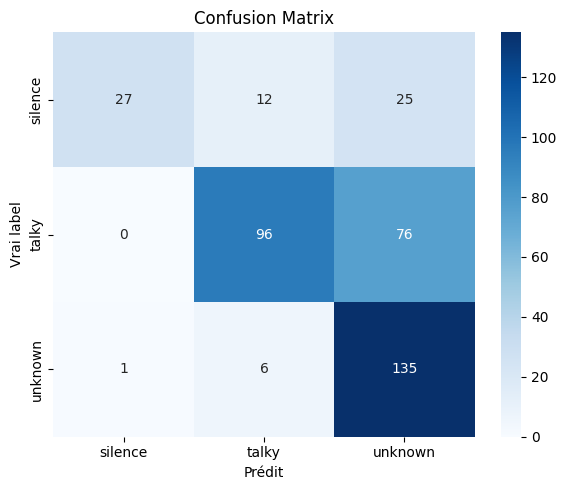

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Prédictions sur le test set (Jonas)
y_pred = np.argmax(model.predict(test_ds), axis=1)
y_true = np.concatenate([y for _, y in test_ds], axis=0)

# Classification report
print(classification_report(y_true, y_pred, target_names=CLASSES))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)
plt.title("Confusion Matrix")
plt.ylabel("Vrai label")
plt.xlabel("Prédit")
plt.tight_layout()
plt.savefig("confusion_matrix_jonas.png", dpi=150)
plt.show()

## Tester les moments de convergence

In [18]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate'])

In [19]:
best_epoch = np.argmax(history.history["val_accuracy"]) + 1
best_val_acc = np.max(history.history["val_accuracy"])

print(f"Best Epoch : {best_epoch}")
print(f"Val Acc : {best_val_acc})")

Best Epoch : 40
Val Acc : 0.9824561476707458)


## Tracer Val accuracy

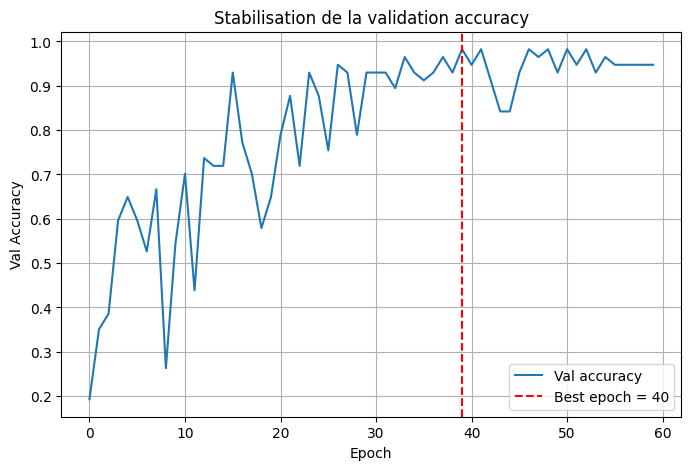

Best val acc: 0.9824561476707458


In [20]:
import numpy as np
import matplotlib.pyplot as plt

val_acc = history.history["val_accuracy"]
best_epoch = np.argmax(val_acc)

plt.figure(figsize=(8,5))

plt.plot(val_acc, label="Val accuracy")
plt.axvline(best_epoch, color="red", linestyle="--", label=f"Best epoch = {best_epoch+1}")

plt.xlabel("Epoch")
plt.ylabel("Val Accuracy")
plt.title("Stabilisation de la validation accuracy")
plt.legend()
plt.grid(True)

plt.show()

print("Best val acc:", val_acc[best_epoch])


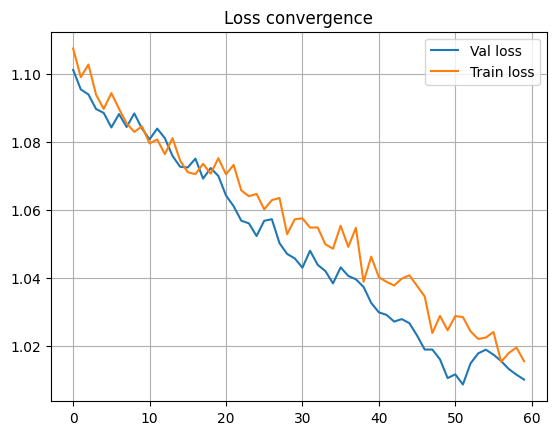

In [21]:
plt.plot(history.history["val_loss"], label="Val loss")
plt.plot(history.history["loss"], label="Train loss")
plt.legend()
plt.grid()
plt.title("Loss convergence")
plt.show()